# Reto 4 · Interpretación de los segmentos

**Malackathon 2026 · Mercedes-Benz · "Clustering the Star"**

Objetivo: traducir los 6 clústeres del modelo K-Means a perfiles de cliente que un equipo de marketing pueda entender y utilizar. Este notebook cubre:

1. Datos de partida
2. Perfilado agregado por clúster
3. Comparación visual de los segmentos
4. Buyer personas: perfil y estrategia comercial de cada segmento
5. Resumen de acciones

## 1. Datos de partida

Usamos la tabla de clientes que guardó el cuaderno 03 (`clientes_clusters.csv`): una fila por cliente con sus datos en **unidades reales**
(euros, años, meses) y la columna `cluster`. No usamos la matriz escalada del modelo, porque sus valores (centrados en 0) no se pueden leer
en términos de negocio.

Añadimos algunas columnas auxiliares para resumir mejor cada segmento: edad numérica aproximada, vehículo electrificado, financiación activa y modelo AMG.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import plot_style as ps
import mb_features as mf

ps.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_DIR / "clientes_clusters.csv", low_memory=False)
K = df["cluster"].nunique()

# Edad aproximada: punto medio de cada rango (para poder calcular medias)
EDAD_MEDIA = {"<25": 21, "25-34": 29.5, "35-44": 39.5, "45-54": 49.5, "55-64": 59.5, "65+": 70}
df["edad_aprox"] = df["age_range"].map(EDAD_MEDIA)
df["electrificado"] = df["main_engine_concept"].isin(["ELECTRIC", "PLUGIN_HYBRID"])
df["financiacion_activa"] = df["finance_leasing_status"].str.startswith("active")
df["amg"] = df["main_vehicle_type"].str.contains("AMG")
print(f"{len(df):,} clientes · {K} clústeres")
df["cluster"].value_counts().sort_index().rename("clientes").to_frame().T

173,456 clientes · 6 clústeres


cluster,0,1,2,3,4,5
clientes,29388,26245,31980,30809,21510,33524


## 2. Perfilado agregado por clúster

### 2.1 Variables numéricas (medias)

Para cada clúster calculamos la media de las variables principales. La última fila es la media de todos los clientes, que sirve de referencia
para ver si un segmento está por encima o por debajo de lo habitual.

In [2]:
NUMERICAS = {
    "edad_aprox": "Edad aproximada (años)",
    "purchasing_power_per_household_eur": "Poder adquisitivo por hogar (€)",
    "months_as_mb_customer": "Meses como cliente",
    "main_vehicle_age_years": "Antigüedad del vehículo (años)",
    "warranty_visit_frequency": "Visitas al taller por vehículo",
    "currently_connected_vehicles": "Vehículos conectados",
    "n_vehicles_history": "Vehículos en su historial",
}
PORCENTAJES = {
    "has_telemetry": "Con telemetría (%)",
    "electrificado": "Electrificado: EV o PHEV (%)",
    "financiacion_activa": "Financiación activa (%)",
    "main_is_van": "Furgoneta (%)",
    "amg": "AMG (%)",
}

g = df.groupby("cluster")
perfil = pd.concat([g[list(NUMERICAS)].mean(), g[list(PORCENTAJES)].mean() * 100], axis=1)
perfil.insert(0, "% de clientes", g.size() / len(df) * 100)
media_global = pd.concat([df[list(NUMERICAS)].mean(), df[list(PORCENTAJES)].mean() * 100])
media_global["% de clientes"] = 100
perfil.loc["Media global"] = media_global
perfil = perfil.rename(columns={**NUMERICAS, **PORCENTAJES})
perfil.round(1)

,% de clientes,Edad aproximada (años),Poder adquisitivo por hogar (€),Meses como cliente,Antigüedad del vehículo (años),Visitas al taller por vehículo,Vehículos conectados,Vehículos en su historial,Con telemetría (%),Electrificado: EV o PHEV (%),Financiación activa (%),Furgoneta (%),AMG (%)
cluster,,,,,,,,,,,,,
0,16.9,60.6,89103.5,15.0,2.6,0.6,0.9,1.4,43.4,35.5,9.8,16.6,4.9
1,15.1,48.7,112802.6,38.6,3.8,2.9,1.1,2.1,71.0,36.4,35.1,0.0,26.9
2,18.4,44.8,114710.2,37.2,2.8,2.7,1.2,2.2,64.6,25.2,96.3,12.4,13.1
3,17.8,31.8,93453.2,26.8,5.5,1.2,0.9,1.4,60.8,9.6,2.5,10.5,14.3
4,12.4,54.9,100161.6,30.6,9.4,0.8,0.9,1.2,43.0,1.3,1.6,8.0,12.2
5,19.3,56.4,118539.9,52.3,5.0,3.9,1.1,2.1,71.8,19.4,4.2,14.6,10.8
Media global,100.0,49.3,105243.5,33.9,4.6,2.1,1.0,1.7,60.0,21.8,26.2,10.8,13.5


### 2.2 Variables categóricas (moda y frecuencia)

Para las variables categóricas mostramos el valor más frecuente de cada clúster (la moda) y qué porcentaje de sus clientes lo tiene.

In [3]:
CATEGORICAS = {
    "age_range": "Rango de edad",
    "country_code": "País",
    "main_engine_concept": "Motorización",
    "main_fuel_type": "Combustible",
    "finance_leasing_status": "Financiación",
    "main_model_class": "Clase de vehículo",
}

def moda_con_frecuencia(s):
    vc = s.value_counts(normalize=True)
    return f"{vc.index[0]} ({vc.iloc[0]:.0%})"

modas = g[list(CATEGORICAS)].agg(moda_con_frecuencia).rename(columns=CATEGORICAS)
modas

,Rango de edad,País,Motorización,Combustible,Financiación,Clase de vehículo
cluster,,,,,,
0,65+ (44%),AT (58%),COMBUSTION (30%),DIESEL (25%),never_active (87%),GLC-Class (27%)
1,45-54 (26%),CH (70%),COMBUSTION (31%),DIESEL (25%),never_active (61%),GLE-/GLS-Class (39%)
2,35-44 (27%),CH (84%),COMBUSTION (43%),UNKNOWN (25%),active_FL_only (91%),GLC-Class (26%)
3,25-34 (46%),CH (55%),COMBUSTION (69%),DIESEL (33%),never_active (95%),A-Class (28%)
4,65+ (30%),CH (62%),COMBUSTION (85%),DIESEL (47%),never_active (97%),C-Class (25%)
5,65+ (29%),CH (80%),COMBUSTION (52%),UNKNOWN (29%),never_active (92%),GLC-Class (22%)


La moda de combustible es `UNKNOWN` en algunos segmentos porque, como se explicó en el cuaderno 02, en los coches de gasolina no siempre se
puede saber si son `PETROL` o `PETROL_PLUS`. Para la motorización y la financiación es más útil ver la distribución completa:

In [4]:
motor = pd.crosstab(df["cluster"], df["main_engine_concept"], normalize="index").mul(100).round(0)
financiacion = pd.crosstab(df["cluster"], df["finance_leasing_status"], normalize="index").mul(100).round(0)
display(motor[["COMBUSTION", "MILD_HYBRID", "PLUGIN_HYBRID", "ELECTRIC", "UNKNOWN"]].rename_axis("Motorización (%)", axis=1))
display(financiacion[["never_active", "was_active", "active_FL_only", "active_FL_and_CASH"]].rename_axis("Financiación (%)", axis=1))

Motorización (%),COMBUSTION,MILD_HYBRID,PLUGIN_HYBRID,ELECTRIC,UNKNOWN
cluster,,,,,
0,30.0,24.0,18.0,18.0,10.0
1,31.0,17.0,21.0,15.0,16.0
2,43.0,24.0,12.0,13.0,7.0
3,69.0,14.0,6.0,4.0,7.0
4,85.0,3.0,1.0,0.0,11.0
5,52.0,20.0,9.0,10.0,9.0


Financiación (%),never_active,was_active,active_FL_only,active_FL_and_CASH
cluster,,,,
0,87.0,3.0,8.0,2.0
1,61.0,4.0,31.0,4.0
2,0.0,4.0,91.0,5.0
3,95.0,3.0,2.0,1.0
4,97.0,2.0,1.0,0.0
5,92.0,4.0,2.0,3.0


### 2.3 Nombre de cada segmento

Asignamos a cada clúster un nombre de negocio a partir de su rasgo más distintivo. Lo hacemos con reglas sobre el perfil (por ejemplo, "el
clúster con más financiación activa es el de leasing") en lugar de escribir el número a mano, para que el nombre siga siendo correcto aunque
el modelo se vuelva a entrenar y los clústeres cambien de número.

In [5]:
p = perfil.drop(index="Media global")
pendientes = set(p.index)

def asignar(columna, nombre, mayor=True):
    candidatos = p.loc[sorted(pendientes), columna]
    c = candidatos.idxmax() if mayor else candidatos.idxmin()
    pendientes.discard(c)
    return c, nombre

reglas = [
    ("Financiación activa (%)", "El Conductor en Leasing"),
    ("Antigüedad del vehículo (años)", "El Veterano a Renovar"),
    ("AMG (%)", "El Ejecutivo Premium AMG"),
    ("Meses como cliente", "El Fiel del Taller Oficial"),
]
NOMBRES = dict(asignar(col, nombre) for col, nombre in reglas)
c, n = asignar("Edad aproximada (años)", "El Joven Aspiracional", mayor=False); NOMBRES[c] = n
NOMBRES[pendientes.pop()] = "El Sénior Recién Llegado"
assert len(set(NOMBRES.values())) == K

df["segmento"] = df["cluster"].map(NOMBRES)
pd.DataFrame({"segmento": NOMBRES, "% de clientes": p["% de clientes"].round(1)}).sort_index().rename_axis("clúster")

,segmento,% de clientes
clúster,,
0,El Sénior Recién Llegado,16.9
1,El Ejecutivo Premium AMG,15.1
2,El Conductor en Leasing,18.4
3,El Joven Aspiracional,17.8
4,El Veterano a Renovar,12.4
5,El Fiel del Taller Oficial,19.3


## 3. Comparación visual de los segmentos

### 3.1 Mapa de calor

Cada celda indica cuánto se aleja la media del clúster de la media global, en desviaciones típicas. **Naranja** significa por encima de la
media y **azul**, por debajo. Así se ve de un vistazo qué hace distinto a cada segmento.

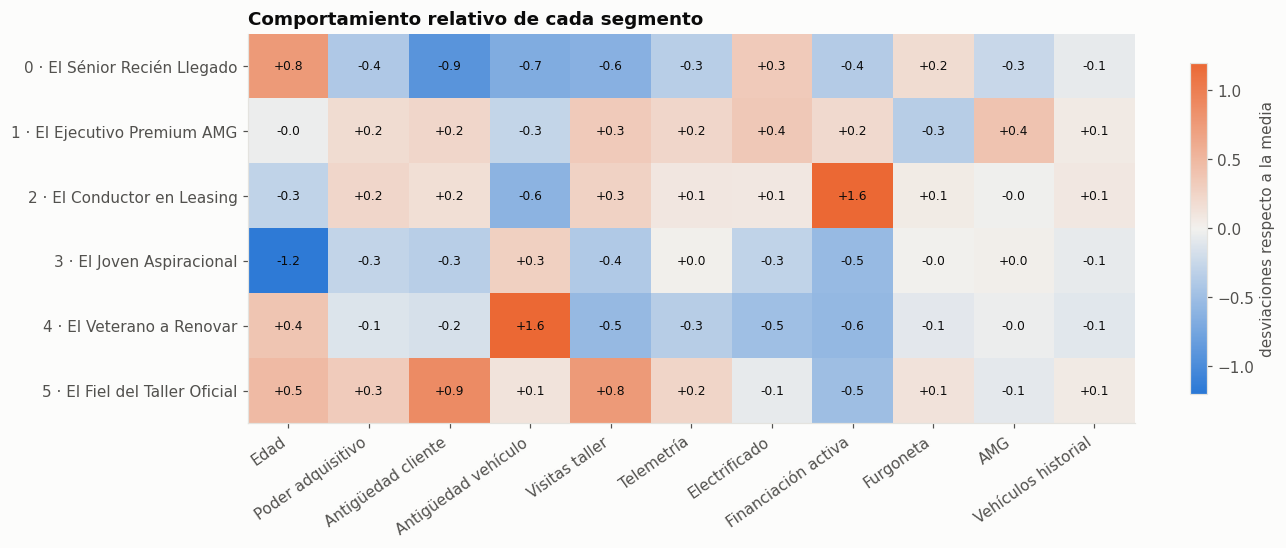

In [6]:
VARS_COMP = {
    "edad_aprox": "Edad", "purchasing_power_per_household_eur": "Poder adquisitivo", "months_as_mb_customer": "Antigüedad cliente",
    "main_vehicle_age_years": "Antigüedad vehículo", "warranty_visit_frequency": "Visitas taller", "has_telemetry": "Telemetría",
    "electrificado": "Electrificado", "financiacion_activa": "Financiación activa", "main_is_van": "Furgoneta", "amg": "AMG",
    "n_vehicles_history": "Vehículos historial",
}
base = df[list(VARS_COMP)].astype(float)
z = ((base.groupby(df["cluster"]).mean() - base.mean()) / base.std()).rename(columns=VARS_COMP)

fig, ax = plt.subplots(figsize=(13, 4.6))
im = ax.imshow(z.values, cmap=ps.DIVERGING, vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(z.shape[1]), z.columns, rotation=35, ha="right")
ax.set_yticks(range(K), [f"{i} · {NOMBRES[i]}" for i in z.index]); ax.grid(False)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.values[i, j]:+.1f}", ha="center", va="center", fontsize=8, color=ps.INK)
fig.colorbar(im, ax=ax, shrink=0.85, label="desviaciones respecto a la media")
ax.set_title("Comportamiento relativo de cada segmento")
fig.savefig(FIG_DIR / "04b_heatmap.png"); plt.show()

### 3.2 Gráficos de radar

El radar muestra el "perfil" de cada segmento en las mismas variables. Cada eje va del clúster con el valor más bajo (centro) al más alto
(borde), y la línea gris discontinua es la media de todos los clientes. Usamos un radar por clúster porque seis polígonos superpuestos serían ilegibles.

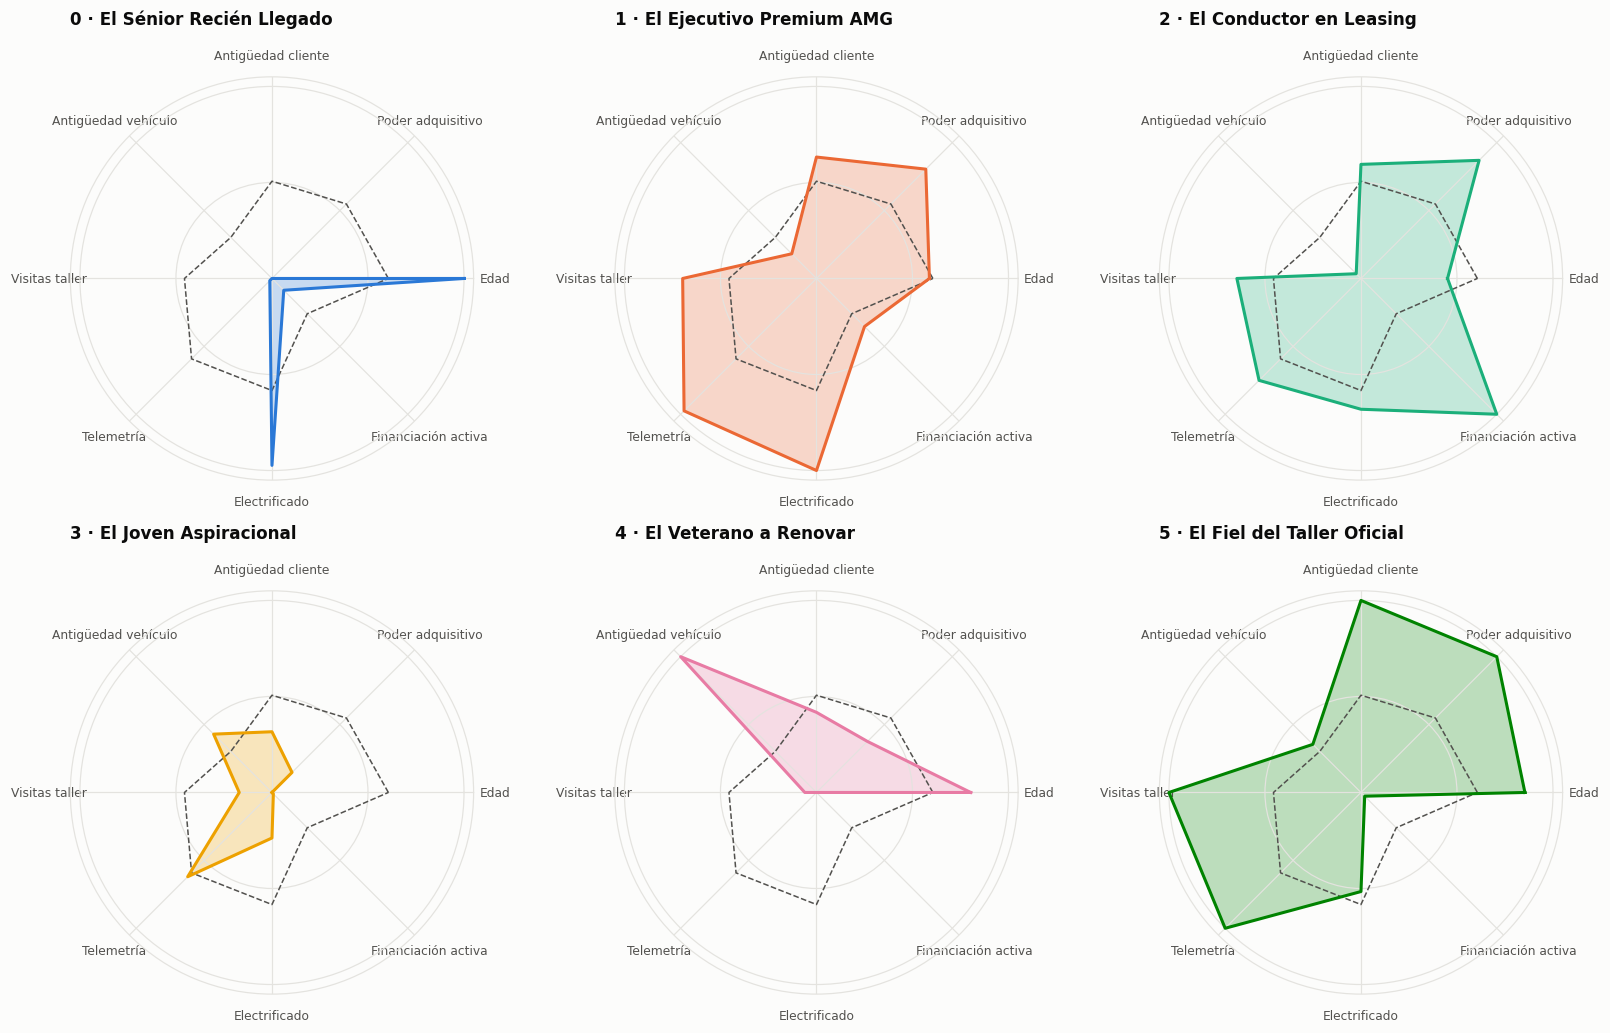

In [7]:
RADAR = ["Edad", "Poder adquisitivo", "Antigüedad cliente", "Antigüedad vehículo", "Visitas taller",
         "Telemetría", "Electrificado", "Financiación activa"]
medias = base.groupby(df["cluster"]).mean().rename(columns=VARS_COMP)[RADAR]
glob = base.mean().rename(VARS_COMP)[RADAR]
lo, hi = medias.min(), medias.max()
norm = (medias - lo) / (hi - lo)
norm_glob = (glob - lo) / (hi - lo)

angulos = np.linspace(0, 2 * np.pi, len(RADAR), endpoint=False).tolist() + [0]
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), subplot_kw={"polar": True})
for ax, c in zip(axes.ravel(), norm.index):
    vals = norm.loc[c].tolist() + [norm.loc[c].iloc[0]]
    ax.plot(angulos, norm_glob.tolist() + [norm_glob.iloc[0]], color=ps.INK_2, lw=1, ls="--")
    ax.plot(angulos, vals, color=ps.SERIES[c], lw=2)
    ax.fill(angulos, vals, color=ps.SERIES[c], alpha=0.25)
    ax.set_xticks(angulos[:-1], RADAR, fontsize=8)
    ax.set_yticks([0.5, 1]); ax.set_yticklabels([]); ax.set_ylim(0, 1.05)
    ax.set_title(f"{c} · {NOMBRES[c]}", pad=16, fontsize=11)
fig.tight_layout(); fig.savefig(FIG_DIR / "04b_radar.png"); plt.show()

## 4. Buyer personas

Las cifras de cada ficha salen de las tablas de la sección 2 (medias y porcentajes del segmento frente a la media global).

---

#### El Sénior Recién Llegado (≈17 % de los clientes)

**Perfil.** Clientes de mayor edad (siete de cada diez tienen 55 años o más) que acaban de llegar a la marca: llevan de media unos 15 meses,
la menor antigüedad de todos los segmentos, y conducen un coche muy reciente (unos 2,6 años). Es el segmento con más furgonetas y con un
peso alto de electrificados, y el de menor poder adquisitivo.

**Rasgos distintivos.** Antigüedad como cliente muy baja, edad alta, pocas visitas al taller todavía y menos telemetría que la media. El 16 % ya
no tiene ningún vehículo conectado.

**Estrategia recomendada.**
- **Bienvenida acompañada:** llamada de seguimiento y sesión presencial para configurar el coche y la app; materiales sencillos por correo postal.
- **Primer plan de mantenimiento** para consolidar la relación con el taller oficial desde el principio.
- **Soporte a la electrificación:** asesoramiento sobre carga en casa para quienes tienen eléctrico o híbrido enchufable.

---

#### El Ejecutivo Premium AMG (≈15 %)

**Perfil.** Clientes de mediana edad (moda 45-54 años) con alto poder adquisitivo y los vehículos de **mayor gama**: GLE/GLS y Clase E son
mayoría, y más de una cuarta parte conduce un AMG. Es el segmento con más híbridos enchufables y tiene una telemetría alta.

**Rasgos distintivos.** Máximo porcentaje de AMG y de gama superior, buena conectividad, uso del taller por encima de la media y una parte
relevante con financiación activa. No tiene furgonetas.

**Estrategia recomendada.**
- **Upsell a la gama más alta:** presentaciones privadas de AMG, EQS y Maybach, y experiencias de conducción en circuito.
- **Servicio concierge:** recogida y entrega del vehículo en el taller, vehículo de sustitución de su misma gama.
- **Renovación anticipada** para quienes tienen el leasing a punto de vencer.

---

#### El Conductor en Leasing (≈18 %)

**Perfil.** Clientes de 35-44 años, mayoritariamente de Suiza y con alto poder adquisitivo, en los que **prácticamente todos tienen un
contrato de financiación activo** con Mercedes-Benz. Conducen un coche reciente (unos 2,8 años) y usan el taller oficial con regularidad.

**Rasgos distintivos.** Financiación activa en más del 90 % de los clientes, edad intermedia, coche nuevo y casi todos con un vehículo conectado.

**Estrategia recomendada.**
- **Programa de fin de contrato:** contactar meses antes del vencimiento con la oferta del siguiente modelo para encadenar un nuevo leasing.
- **Mantenimiento incluido en la cuota** y paquetes de servicios conectados.
- **Comunicación digital** (app y email), con el calendario del contrato como guía de los contactos.

---

#### El Joven Aspiracional (≈18 %)

**Perfil.** El segmento **más joven**: dos de cada tres tienen menos de 35 años. Conducen compactos (Clase A, Clase C, CLA) con unos 5,5 años
de antigüedad, mayoritariamente de combustión, y casi nunca han financiado con la marca. Su poder adquisitivo está por debajo de la media.

**Rasgos distintivos.** Edad baja, coche de entrada a la gama y ya con algunos años, sin relación con la financiera. El 15 % no tiene ningún
vehículo conectado actualmente.

**Estrategia recomendada.**
- **Primera financiación:** ofertas de renting o leasing con cuota accesible para dar el salto a un coche nuevo.
- **Vehículos de ocasión certificados** como puerta de entrada a un modelo más reciente.
- **Canales digitales y redes sociales**, con mensajes de aspiración y comunidad de marca.

---

#### El Veterano a Renovar (≈12 %)

**Perfil.** Clientes de edad alta con el **vehículo más antiguo** de la base (unos 9,4 años), casi siempre de combustión y en buena parte diésel.
Prácticamente ninguno tiene financiación activa, usan poco el taller oficial y tienen menos telemetría que la media.

**Rasgos distintivos.** Máxima antigüedad del vehículo, mínima electrificación (prácticamente nula) y el 16 % sin ningún vehículo conectado:
riesgo real de abandonar la marca.

**Estrategia recomendada.**
- **Campaña de renovación:** tasación del vehículo actual y plan de cambio, con prueba de modelos híbridos y eléctricos.
- **Recuperación de posventa:** mantenimiento a precio cerrado para coches de más de 8 años, para que vuelvan al taller oficial.
- **Contacto por teléfono y correo postal**, más adecuados para este perfil.

---

#### El Fiel del Taller Oficial (≈19 %)

**Perfil.** Los clientes **más antiguos** de la marca (más de 4 años de media) y con el **mayor poder adquisitivo**, mayoritariamente suizos y
de edad alta. Son los que **más usan el taller oficial** (unas 4 visitas por vehículo en garantía) y tienen la telemetría más alta. Compran
al contado: casi ninguno ha usado la financiera.

**Rasgos distintivos.** Máxima fidelidad y uso de posventa, alto valor económico y relación con la marca consolidada.

**Estrategia recomendada.**
- **Programa de fidelización** con ventajas exclusivas: revisiones prioritarias, eventos de marca y descuentos en accesorios.
- **Extensión de garantía y planes de mantenimiento premium**, que encajan con su uso intensivo del taller.
- **Venta del siguiente vehículo al contado** con condiciones preferentes, sin depender de la financiación.

## 5. Resumen de acciones

La tabla resume la acción principal para cada segmento en las cuatro líneas de marketing del reto. Se guarda también en `reports/` para el
equipo de marketing.

In [8]:
ACCIONES = {
    "El Sénior Recién Llegado": ("Asesoramiento para el primer cambio", "Primer plan de mantenimiento", "Bienvenida acompañada", "Teléfono y correo postal"),
    "El Ejecutivo Premium AMG": ("AMG, EQS y Maybach", "Servicio concierge", "Experiencias exclusivas", "Gestor personal"),
    "El Conductor en Leasing": ("Siguiente modelo al fin del contrato", "Mantenimiento incluido en la cuota", "Renovación encadenada", "App y email"),
    "El Joven Aspiracional": ("Primera financiación y ocasión certificada", "Revisión con precio cerrado", "Comunidad de marca", "Digital y redes sociales"),
    "El Veterano a Renovar": ("Plan de cambio con tasación", "Mantenimiento a precio cerrado (>8 años)", "Recuperación de cliente", "Teléfono y correo postal"),
    "El Fiel del Taller Oficial": ("Nuevo modelo al contado", "Extensión de garantía premium", "Programa VIP", "Concesionario"),
}
resumen = pd.DataFrame.from_dict(ACCIONES, orient="index",
                                 columns=["Oferta de vehículo", "Plan de mantenimiento", "Fidelización", "Canal de comunicación"])
peso = df.groupby("segmento").size() / len(df) * 100
resumen.insert(0, "% de clientes", peso.reindex(resumen.index).round(1))
resumen.index.name = "Segmento"
resumen.to_csv(ROOT / "reports" / "fichas_segmentos_k6.csv")
resumen

,% de clientes,Oferta de vehículo,Plan de mantenimiento,Fidelización,Canal de comunicación
Segmento,,,,,
El Sénior Recién Llegado,16.9,Asesoramiento para el primer cambio,Primer plan de mantenimiento,Bienvenida acompañada,Teléfono y correo postal
El Ejecutivo Premium AMG,15.1,"AMG, EQS y Maybach",Servicio concierge,Experiencias exclusivas,Gestor personal
El Conductor en Leasing,18.4,Siguiente modelo al fin del contrato,Mantenimiento incluido en la cuota,Renovación encadenada,App y email
El Joven Aspiracional,17.8,Primera financiación y ocasión certificada,Revisión con precio cerrado,Comunidad de marca,Digital y redes sociales
El Veterano a Renovar,12.4,Plan de cambio con tasación,Mantenimiento a precio cerrado (>8 años),Recuperación de cliente,Teléfono y correo postal
El Fiel del Taller Oficial,19.3,Nuevo modelo al contado,Extensión de garantía premium,Programa VIP,Concesionario


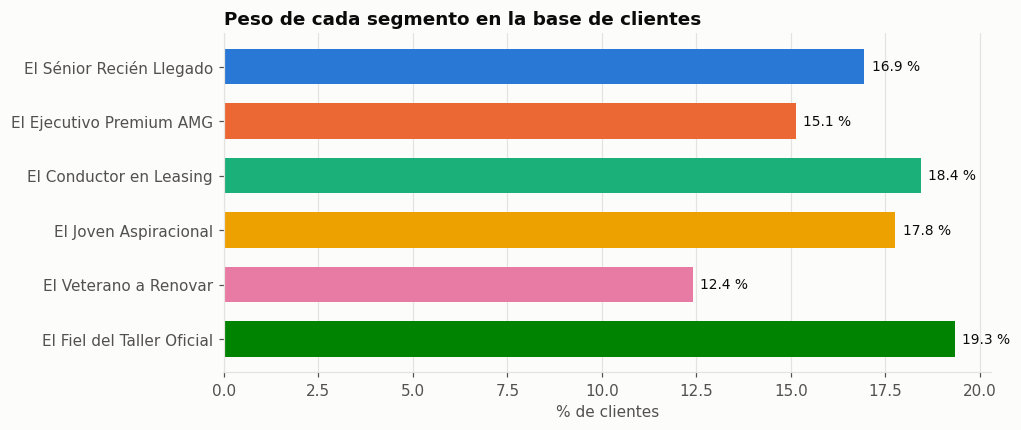

In [9]:
pct = df["segmento"].value_counts(normalize=True).mul(100).reindex(resumen.index)
colores = [ps.SERIES[[k for k, v in NOMBRES.items() if v == s][0]] for s in pct.index]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(pct.index, pct.values, color=colores, height=0.65); ax.invert_yaxis(); ax.set_axisbelow(True)
for i, v in enumerate(pct.values):
    ax.text(v + 0.2, i, f"{v:.1f} %", va="center", fontsize=9, color=ps.INK)
ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_xlabel("% de clientes")
ax.set_title("Peso de cada segmento en la base de clientes")
fig.savefig(FIG_DIR / "04b_peso_segmentos.png"); plt.show()

df[["client_id", "cluster", "segmento"]].to_csv(DATA_DIR / "clientes_segmentos_k6.csv", index=False)

Los seis segmentos cubren necesidades distintas y complementarias: captar y consolidar a los recién llegados, subir de gama a los clientes
premium, encadenar contratos de leasing, dar el primer paso a los jóvenes, renovar los vehículos más antiguos y premiar a los clientes más fieles.